Online Shoppers Purchasing Intention Prediction Using Random Forest

Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pandas - for handling datasets



numpy  - for numerical operations



matplotlib - for creating graphs



seaborn - for statistical visualisations

Loading the Dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (2).zip to archive (2) (1).zip


In [ ]:
import zipfile

# Open the zip file and read the specific CSV file
with zipfile.ZipFile('/content/archive (2).zip') as z:
    df = pd.read_csv(z.open('online_shoppers_intention.csv'))

df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


pd.read_csv() reads the CSV dataset



df stores the dataset as a DataFrame



df.head() displays the first 5 rows

Understanding the Dataset

In [ ]:
df.tail()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False
12329,0,0.0,0,0.0,3,21.250000,0.000000,0.066667,0.000000,0.0,Nov,3,2,1,2,New_Visitor,True,False


df.tail() - displays the last 5 rows.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

df.info() - shows column names, data types and non-null values

In [ ]:
print(df.shape)

(12330, 18)


df.shape - tells us the number of rows and columns

In [ ]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


df.describe() - gives statistical information such as mean, minimum, maximum and standard deviation

Checking the missing values

In [ ]:
print(df.isnull().sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


df.isnull() checks whether each value is missing



.sum() counts the missing values in each column

Checking Duplicate Values

In [ ]:
print(df.duplicated().sum())

125


df.duplicated() identifies repeated rows



.sum() counts the total number of duplicate rows

Checking Data Types

In [ ]:
df.dtypes

,0
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


df.dtypes displays the data type of every column



It also helps us to identify numerical and categorical variables



Incorrect data types may cause problems during data analysis and model building

Checking Unique Values

In [ ]:
print(df.nunique())

Administrative               27
Administrative_Duration    3335
Informational                17
Informational_Duration     1258
ProductRelated              311
ProductRelated_Duration    9551
BounceRates                1872
ExitRates                  4777
PageValues                 2704
SpecialDay                    6
Month                        10
OperatingSystems              8
Browser                      13
Region                        9
TrafficType                  20
VisitorType                   3
Weekend                       2
Revenue                       2
dtype: int64


df.nunique() counts the distinct values in each column.



It helps us understand the variety of values.



It can help identify columns that contain only one value or unexpected categories.

Data Cleaning

In [ ]:
df[df.duplicated(keep=False)].head(10)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


In [ ]:
df.drop_duplicates(inplace=True)

print("Dataset Shape After Removing Duplicates:")
print(df.shape)

Dataset Shape After Removing Duplicates:
(12205, 18)


In [ ]:
print("Remaining Duplicate Rows:", df.duplicated().sum())

Remaining Duplicate Rows: 0


Data cleaning helps identify and handle missing values, duplicate records, and incorrect data to improve data quality before model training.

Exploratory Data Analysis

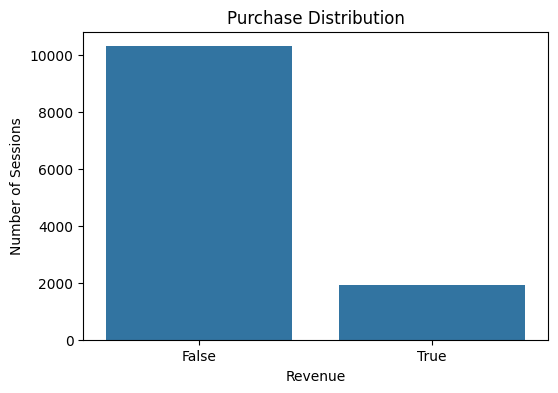

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Revenue', data=df)
plt.title('Purchase Distribution')
plt.xlabel('Revenue')
plt.ylabel('Number of Sessions')
plt.show()

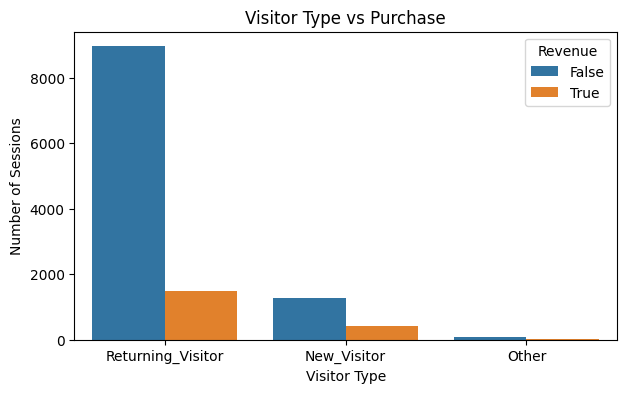

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(x='VisitorType', hue='Revenue', data=df)
plt.title('Visitor Type vs Purchase')
plt.xlabel('Visitor Type')
plt.ylabel('Number of Sessions')
plt.show()

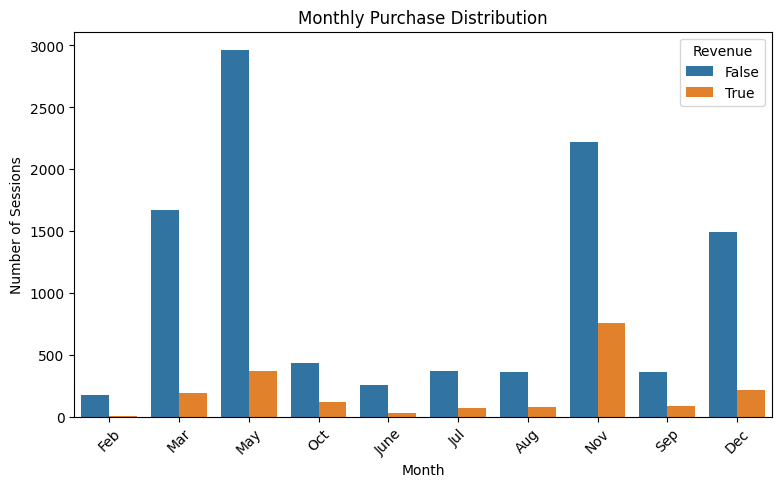

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(x='Month', hue='Revenue', data=df)
plt.title('Monthly Purchase Distribution')
plt.xlabel('Month')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=45)
plt.show()

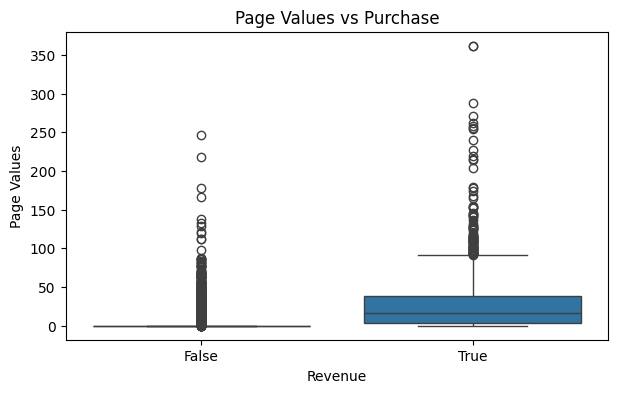

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(x='Revenue', y='PageValues', data=df)
plt.title('Page Values vs Purchase')
plt.xlabel('Revenue')
plt.ylabel('Page Values')
plt.show()

Data Preprocessing

In [ ]:
X = df.drop('Revenue', axis=1)
y = df['Revenue'].astype(int)

X = pd.get_dummies(X, drop_first=True)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (12205, 26)
Target Shape: (12205,)


- To prepare data for model training.
- To convert categorical data into numerical values.
- To separate input features (X) and target (y)

Splitting the Dataset

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (9764, 26)
Testing Features: (2441, 26)
Training Target: (9764,)
Testing Target: (2441,)


To train the model using one portion of the data and evaluate its performance on unseen data to check its prediction accuracy.

Random Forest Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


Random Forest uses multiple decision trees to classify whether a website visitor will make a purchase.

Model Prediction

In [ ]:
y_pred = rf_model.predict(X_test)

print("Model Predictions:")
print(y_pred[:10])

Model Predictions:
[0 0 0 0 0 1 0 0 0 0]


To predict whether website visitors will make a purchase based on the testing data.

Model Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.9082343301925441

Confusion Matrix:
[[1991   68]
 [ 156  226]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      2059
           1       0.77      0.59      0.67       382

    accuracy                           0.91      2441
   macro avg       0.85      0.78      0.81      2441
weighted avg       0.90      0.91      0.90      2441



To measure the model's prediction performance using accuracy, confusion matrix, precision, recall and F1-score.

Confusion Matrix Visualization

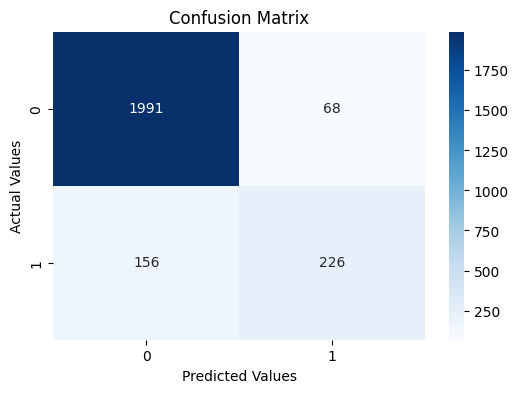

In [ ]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.show()

To visually compare actual and predicted results and understand the model's classification performance.

Feature Importance

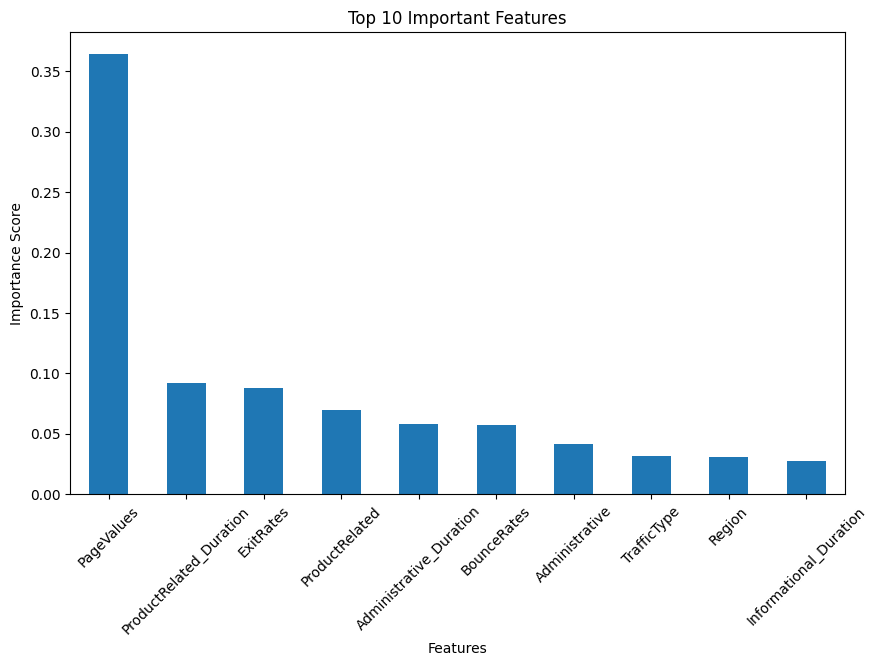

In [ ]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
feature_importance.head(10).plot(kind='bar')
plt.title('Top 10 Important Features')
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.xticks(rotation=45)
plt.show()

To identify the most influential features used by the model for making predictions.

Model Performance Improvement

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best F1 Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}
Best F1 Score: 0.6464456588334769


To find the best combination of model settings to improve prediction performance.

Evaluating the Tuned Model

In [ ]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

print("Tuned Model Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

print("\nTuned Classification Report:")
print(classification_report(y_test, y_pred_tuned))

Tuned Model Accuracy: 0.9037279803359279

Tuned Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.94      2059
           1       0.75      0.58      0.65       382

    accuracy                           0.90      2441
   macro avg       0.84      0.77      0.80      2441
weighted avg       0.90      0.90      0.90      2441



 To evaluate the tuned model on unseen testing data and compare its performance with the original model.

Model Comparison

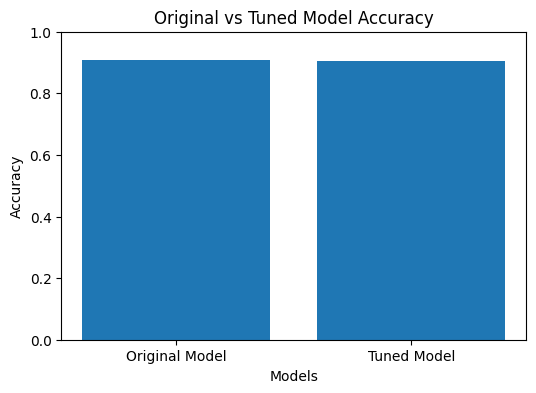

In [40]:
models = ['Original Model', 'Tuned Model']
accuracies = [
    accuracy_score(y_test, y_pred),
    accuracy_score(y_test, y_pred_tuned)
]

plt.figure(figsize=(6, 4))
plt.bar(models, accuracies)
plt.title('Original vs Tuned Model Accuracy')
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

Final Conclusion

In [41]:
print("Project Completed Successfully!")
print("Best Test Accuracy: 90.82%")
print("Selected Model: Original Random Forest Classifier")

Project Completed Successfully!
Best Test Accuracy: 90.82%
Selected Model: Original Random Forest Classifier


To summarize the project outcome and identify the better-performing model.